# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:

caminho = r"C:\Users\joaod\Downloads\archive\flags.csv"

df = pd.read_csv(caminho, sep=";")
print("Dataset carregado com sucesso.")

df_antes = df.copy()
df.head()

Dataset carregado com sucesso.


,name,image,landmass,zone,area,population,language,religion,bars,stripes,...,saltires,quarters,sunstars,crescent,triangle,icon,animate,text,topleft,botright
0,Afghanistan,https://upload.wikimedia.org/wikipedia/commons...,5,1,648,16,10,2,0,3,...,0,0,1,0,0,1,0,0,black,green
1,Albania,https://upload.wikimedia.org/wikipedia/commons...,3,1,29,3,6,6,0,0,...,0,0,1,0,0,0,1,0,red,red
2,Algeria,https://upload.wikimedia.org/wikipedia/commons...,4,1,2388,20,8,2,2,0,...,0,0,1,1,0,0,0,0,green,white
3,American-Samoa,https://upload.wikimedia.org/wikipedia/commons...,6,3,0,0,1,1,0,0,...,0,0,0,0,1,1,1,0,blue,red
4,Andorra,https://upload.wikimedia.org/wikipedia/commons...,3,1,0,0,6,0,3,0,...,0,0,0,0,0,0,0,0,blue,red


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o meu dataset é o *Flags* (bandeiras de países), que traz, para cada país, atributos geográficos (continente/`landmass`, `zone`, `area`, `population`), atributos culturais (`language`, `religion`) e atributos visuais da bandeira (`mainhue`, `topleft`, `botright`, entre outros). Quantas linhas vocês esperam que esse dataset tenha — dezenas, centenas ou milhares de países?

### Dimensão e Tipos de Dados

In [3]:
df.shape

(193, 31)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 31 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        193 non-null    object
 1   image       75 non-null     object
 2   landmass    193 non-null    int64 
 3   zone        193 non-null    int64 
 4   area        193 non-null    int64 
 5   population  193 non-null    int64 
 6   language    193 non-null    int64 
 7   religion    193 non-null    int64 
 8   bars        193 non-null    int64 
 9   stripes     193 non-null    int64 
 10  colours     193 non-null    int64 
 11  red         193 non-null    int64 
 12  green       193 non-null    int64 
 13  blue        193 non-null    int64 
 14  gold        193 non-null    int64 
 15  white       193 non-null    int64 
 16  black       193 non-null    int64 
 17  orange      193 non-null    int64 
 18  mainhue     193 non-null    object
 19  circles     193 non-null    int64 
 20  crosses   

In [5]:
df.describe()

,landmass,zone,area,population,language,religion,bars,stripes,colours,red,...,circles,crosses,saltires,quarters,sunstars,crescent,triangle,icon,animate,text
count,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,...,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000,193.000000
mean,3.580311,2.207254,689.284974,23.243523,5.357513,2.202073,0.455959,1.544041,3.466321,0.792746,...,0.170984,0.150259,0.093264,0.150259,1.388601,0.056995,0.139896,0.253886,0.202073,0.082902
std,1.552896,1.310435,2171.379930,92.172550,3.497269,2.060440,1.040522,2.331706,1.303103,0.406393,...,0.464116,0.386238,0.291559,0.436860,4.407531,0.232436,0.347782,0.436365,0.402590,0.276450
min,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,1.000000,9.000000,0.000000,2.000000,1.000000,0.000000,0.000000,3.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4.000000,2.000000,111.000000,4.000000,6.000000,1.000000,0.000000,0.000000,3.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,5.000000,4.000000,463.000000,14.000000,9.000000,4.000000,0.000000,3.000000,4.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,6.000000,4.000000,22402.000000,1008.000000,10.000000,7.000000,5.000000,14.000000,8.000000,1.000000,...,4.000000,2.000000,1.000000,4.000000,50.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Duplicadas

In [6]:
df.duplicated().sum()

np.int64(0)

### Criando uma variável alvo (proxy) para a análise

O dataset Flags não vem com uma variável-alvo binária pronta como o Heart Disease (que tinha `num`). Para poder reaproveitar, ao longo da aula, a mesma lógica de comparar duas classes por cor (rosa vs. roxo) nas distribuições, criei uma variável : `population_category`, que separa os países em `Low_Pop` (população até a mediana) e `High_Pop` (população acima da mediana). Essa variável não é um "alvo" no sentido de doença ou desfecho real, mas cumpre o mesmo papel.

In [7]:
df["population_category"] = np.where(df["population"] > df["population"].median(), "High_Pop", "Low_Pop")
print(df["population_category"].value_counts())
df.head()

population_category
Low_Pop     101
High_Pop     92
Name: count, dtype: int64


,name,image,landmass,zone,area,population,language,religion,bars,stripes,...,quarters,sunstars,crescent,triangle,icon,animate,text,topleft,botright,population_category
0,Afghanistan,https://upload.wikimedia.org/wikipedia/commons...,5,1,648,16,10,2,0,3,...,0,1,0,0,1,0,0,black,green,High_Pop
1,Albania,https://upload.wikimedia.org/wikipedia/commons...,3,1,29,3,6,6,0,0,...,0,1,0,0,0,1,0,red,red,Low_Pop
2,Algeria,https://upload.wikimedia.org/wikipedia/commons...,4,1,2388,20,8,2,2,0,...,0,1,1,0,0,0,0,green,white,High_Pop
3,American-Samoa,https://upload.wikimedia.org/wikipedia/commons...,6,3,0,0,1,1,0,0,...,0,0,0,1,1,1,0,blue,red,Low_Pop
4,Andorra,https://upload.wikimedia.org/wikipedia/commons...,3,1,0,0,6,0,3,0,...,0,0,0,0,0,0,0,blue,red,Low_Pop


## 2. Dados Faltantes

In [8]:
df.isna().sum()

name                     0
image                  118
landmass                 0
zone                     0
area                     0
population               0
language                 0
religion                 0
bars                     0
stripes                  0
colours                  0
red                      0
green                    0
blue                     0
gold                     0
white                    0
black                    0
orange                   0
mainhue                  0
circles                  0
crosses                  0
saltires                 0
quarters                 0
sunstars                 0
crescent                 0
triangle                 0
icon                     0
animate                  0
text                     0
topleft                  0
botright                 0
population_category      0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: A maioria das imagens das bandeiras dos países estão faltantes provavelmente por causa da dificuldade de achar imagens de bandeiras de países mais "incomuns"

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

Meu dataset apenas teve *image* ausente que é o png das imagens dos países, tirando essas imagens está tudo nos conformes

**As ausencias ocorrem juntas?**

Não há ausências em linhas seguidas, as únicas ausências são as imagens dos países, nada mais



In [9]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['image']
image    118
dtype: int64


No meu caso, apenas uma coluna (`image`) tem valores ausentes. Isso já responde à pergunta de "as ausências ocorrem juntas": como não há uma segunda coluna com ausentes, não existe combinação de ausências para analisar . Apenas confirmo a contagem de ausentes da única coluna afetada.

In [10]:
if len(cols_com_ausentes) >= 2:
    tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
                rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()
else:
    # Só temos uma coluna com ausentes, então não há como cruzar duas colunas de ausência
    col_unica = cols_com_ausentes[0]
    print(f"Apenas uma coluna com ausentes ('{col_unica}'), então não há cruzamento de ausências a fazer.")
    print(f"Total de ausentes em '{col_unica}': {df[col_unica].isna().sum()} ({df[col_unica].isna().mean():.1%} das linhas)")


Apenas uma coluna com ausentes ('image'), então não há cruzamento de ausências a fazer.
Total de ausentes em 'image': 118 (61.1% das linhas)


**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

Para o meu dataset, apenas a coluna image possui dados ausentes. Portanto, a análise de quantas linhas têm duas colunas ausentes ao mesmo tempo não se aplica diretamente aqui. A coluna image possui 118 valores ausentes.

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [11]:
VARS_QUANT = ["landmass", "area", "population", "language", "zone", "religion"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
landmass,3.58,4.00,1.55,1.00,6.00,-0.29,-0.90
area,689.28,111.00,2171.38,0.00,22402.00,6.80,56.86
population,23.24,4.00,92.17,0.00,1008.00,8.55,81.63
language,5.36,6.00,3.50,1.00,10.00,0.08,-1.55
zone,2.21,2.00,1.31,1.00,4.00,0.42,-1.59
religion,2.20,1.00,2.06,0.00,7.00,0.82,-0.67


In [12]:
VARS_QUALI = ["mainhue", "topleft", "botright", "population_category"]

**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Area e population

Isso é coerente com o que vocês esperariam demograficamente (ex: área e população costumam ter poucos países com valores muito altos, puxando a cauda direita, já que a maioria dos países é pequena e pouco populosa)?

Area e population tem skewness altos pois muitos países tem uma população baixa e poucos países tem uma população e uma área muito grande.
Também tanto a area quanto a population tem valores extremos que deixam a cauda mais pesada

### Distribuições de dados

Onde fizer sentido, comparamos "Low_Pop" (rosa) vs. "High_Pop" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


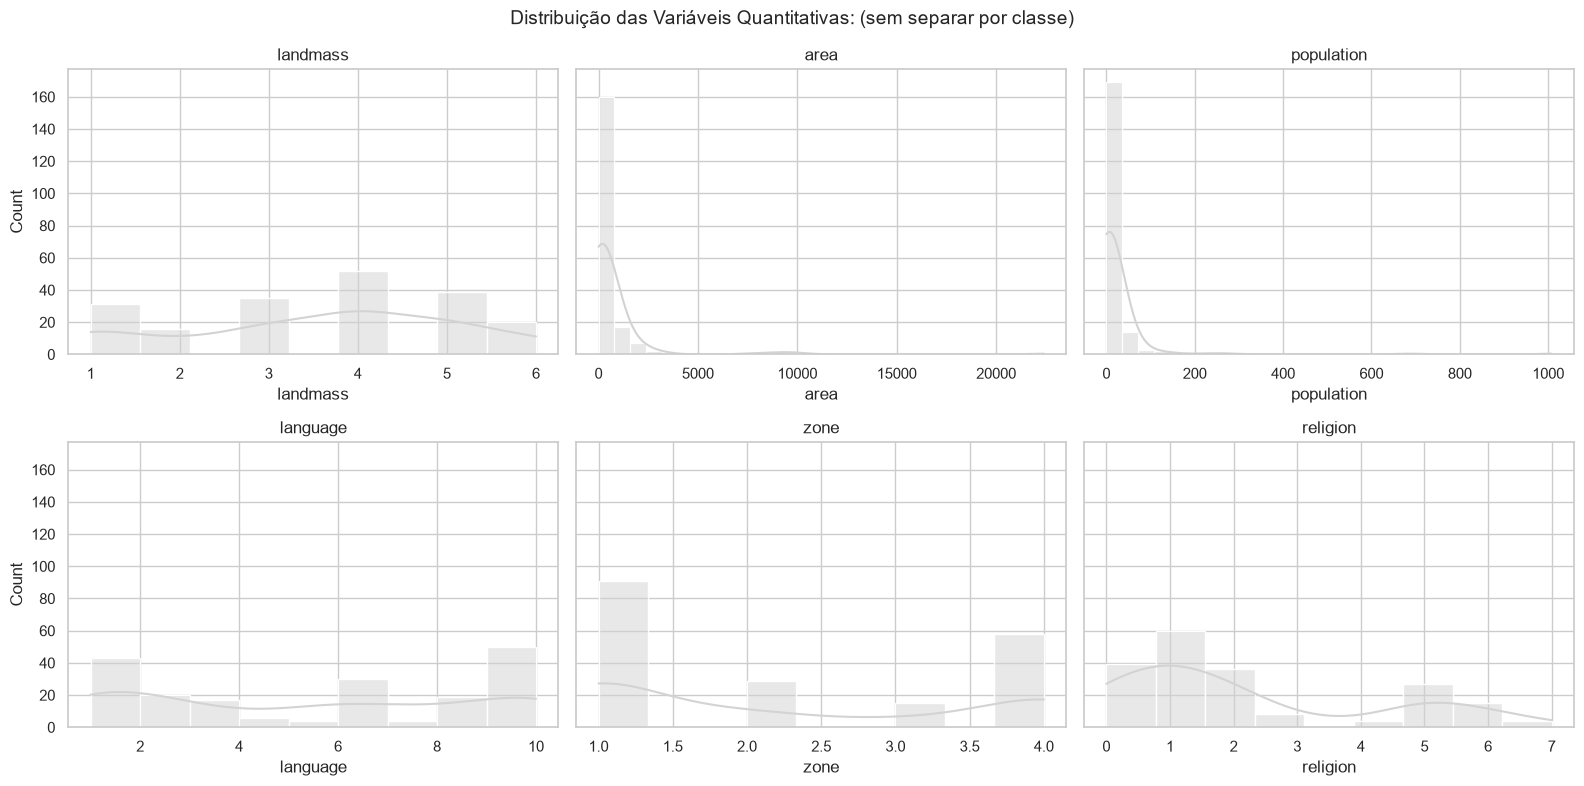

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

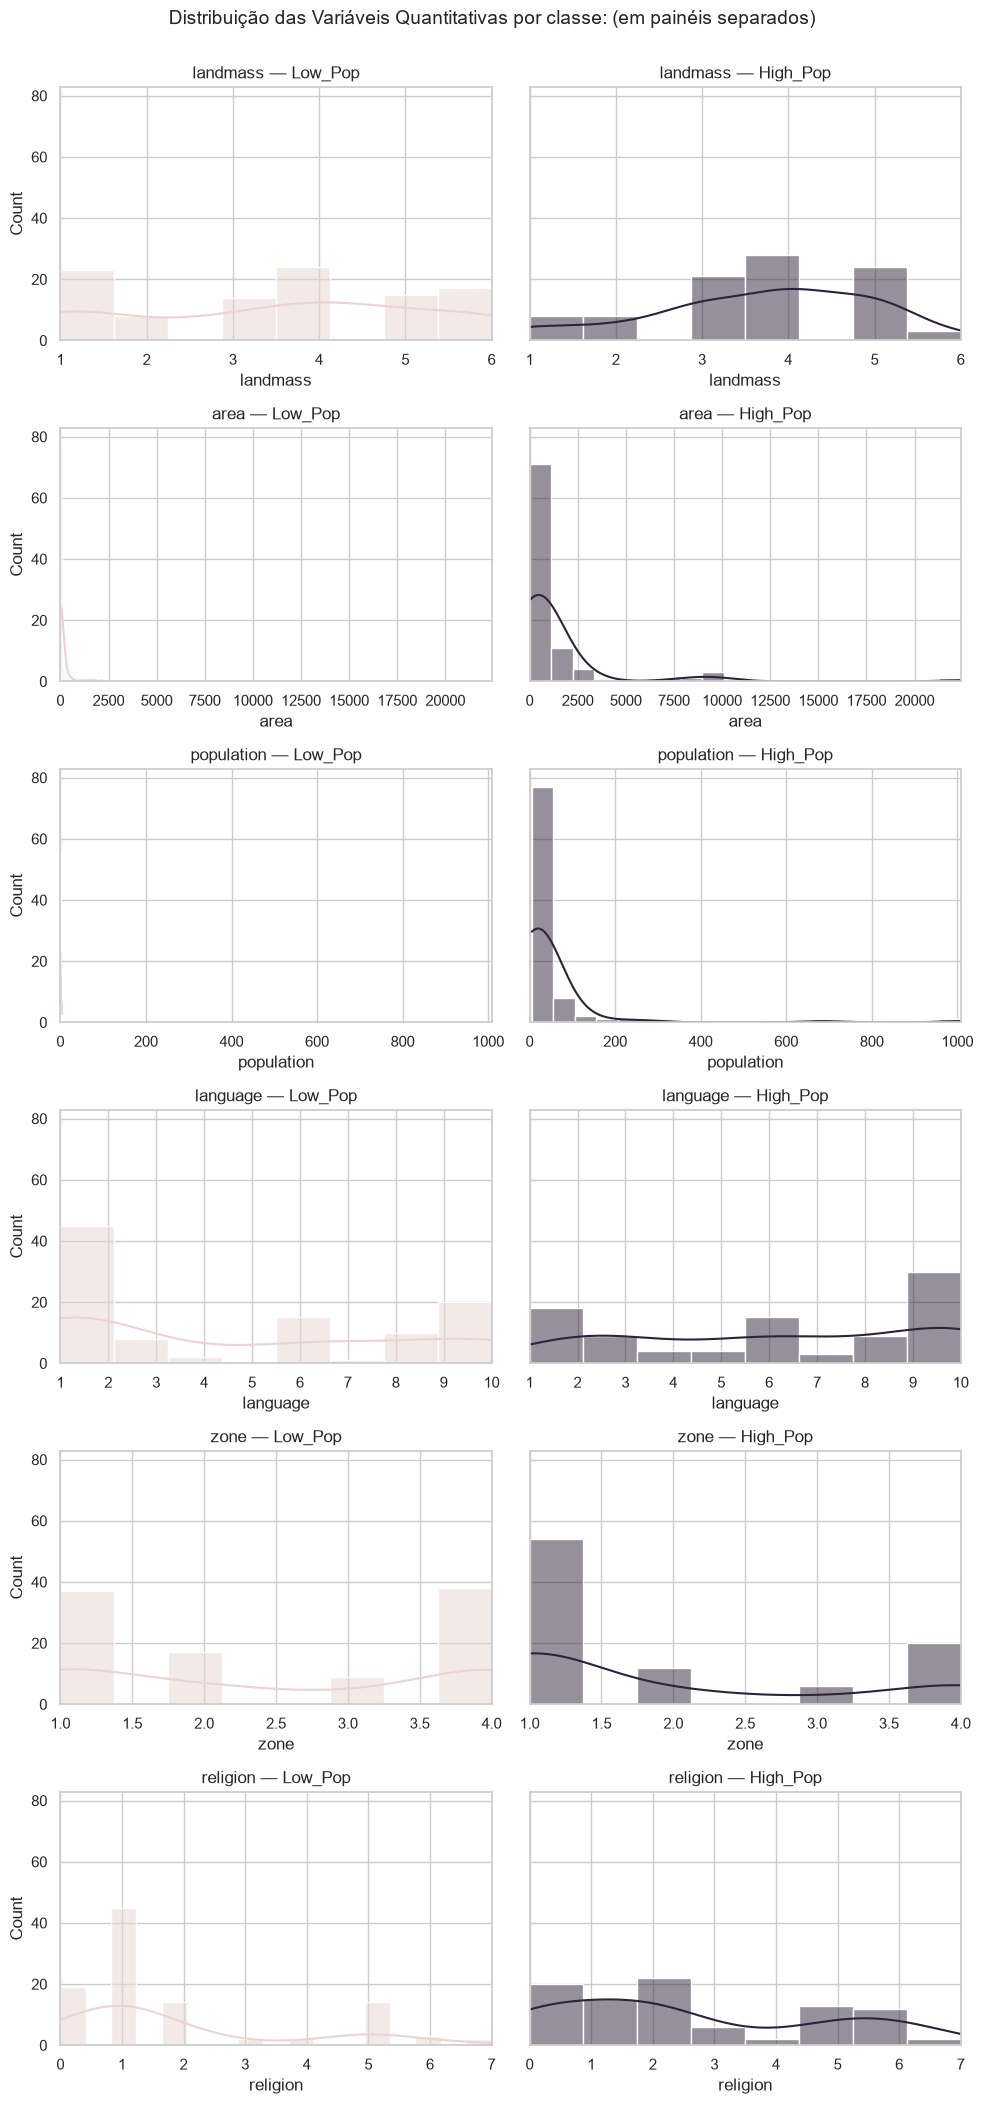

In [14]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

palette_classe = {"Low_Pop": COR_CONTEXTO, "High_Pop": COR_DESTAQUE}

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Low_Pop", COR_CONTEXTO), ("High_Pop", COR_DESTAQUE)]):
        subset = df[df["population_category"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Quantitativas por classe: (em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Low_Pop" e "High_Pop"?


O gráfico compara as características dos países divididos em duas categorias: 'Low_Pop' (baixa população) e 'High_Pop' (alta população).

   As variáveis area e population (área e população) são as que mais se destacam, mostrando diferenças muito claras entre os países com baixa e alta população. Isso é esperado, já que a categoria 'Low_Pop' ou 'High_Pop' foi criada com base na população.

  Para as outras características, como landmass, language, zone e religion (massa terrestre, idioma, fuso e religião), as diferenças entre os grupos 'Low_Pop' e 'High_Pop' são menos acentuadas, mas ainda existem algumas variações nas suas distribuições. Países com 'High_Pop' podem apresentar distribuições um pouco mais diversas ou com picos diferentes para certas categorias.

#### Testes de Aderência

*Será que a área segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `area`.

Shapiro-Wilk — area: estatística=0.3119, p-valor=2.148e-26
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


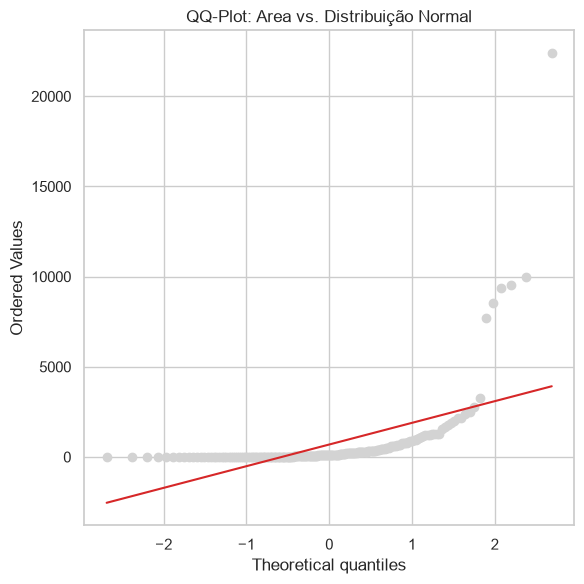

In [15]:
stat_sw, p_valor_sw = stats.shapiro(df["area"].dropna())
print(f"Shapiro-Wilk — area: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — area"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["area"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Area vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com o nosso n (na casa das centenas de países, nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [16]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
landmass,0.9125,0.0,True
area,0.3119,0.0,True
population,0.2269,0.0,True
language,0.8562,0.0,True
zone,0.7420,0.0,True
religion,0.8414,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`population`, população), só pra fixar como essa visualização se lê.

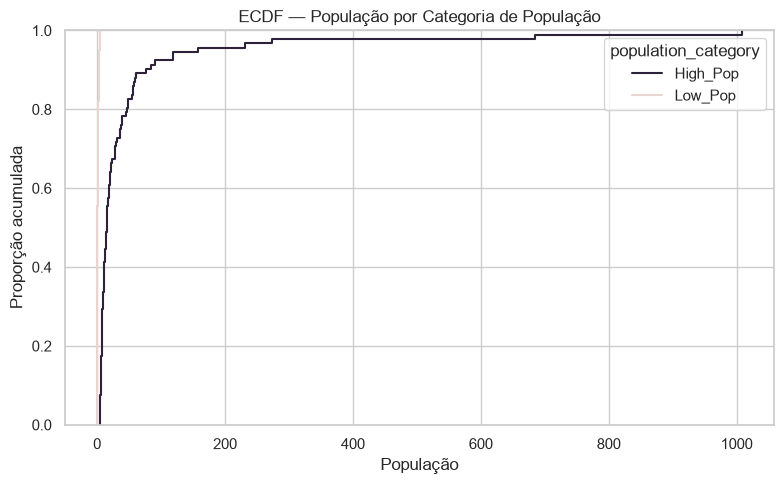

In [17]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="population", hue="population_category",
             palette={"Low_Pop": COR_CONTEXTO, "High_Pop": COR_DESTAQUE})
plt.title("ECDF — População por Categoria de População")
plt.xlabel("População")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos países desse grupo tem população até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de população onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

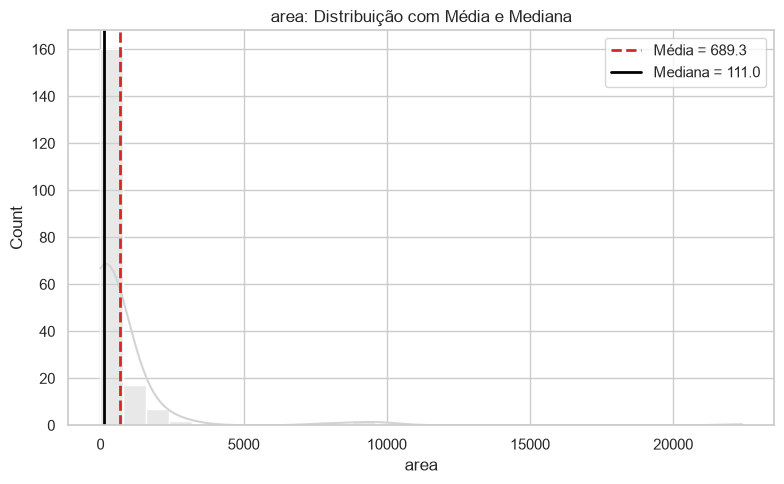

In [18]:
media = df["area"].mean()
mediana = df["area"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="area", kde=True, color=COR_NEUTRA)
plt.axvline(media, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media:.1f}")
plt.axvline(mediana, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana:.1f}")
plt.title("area: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

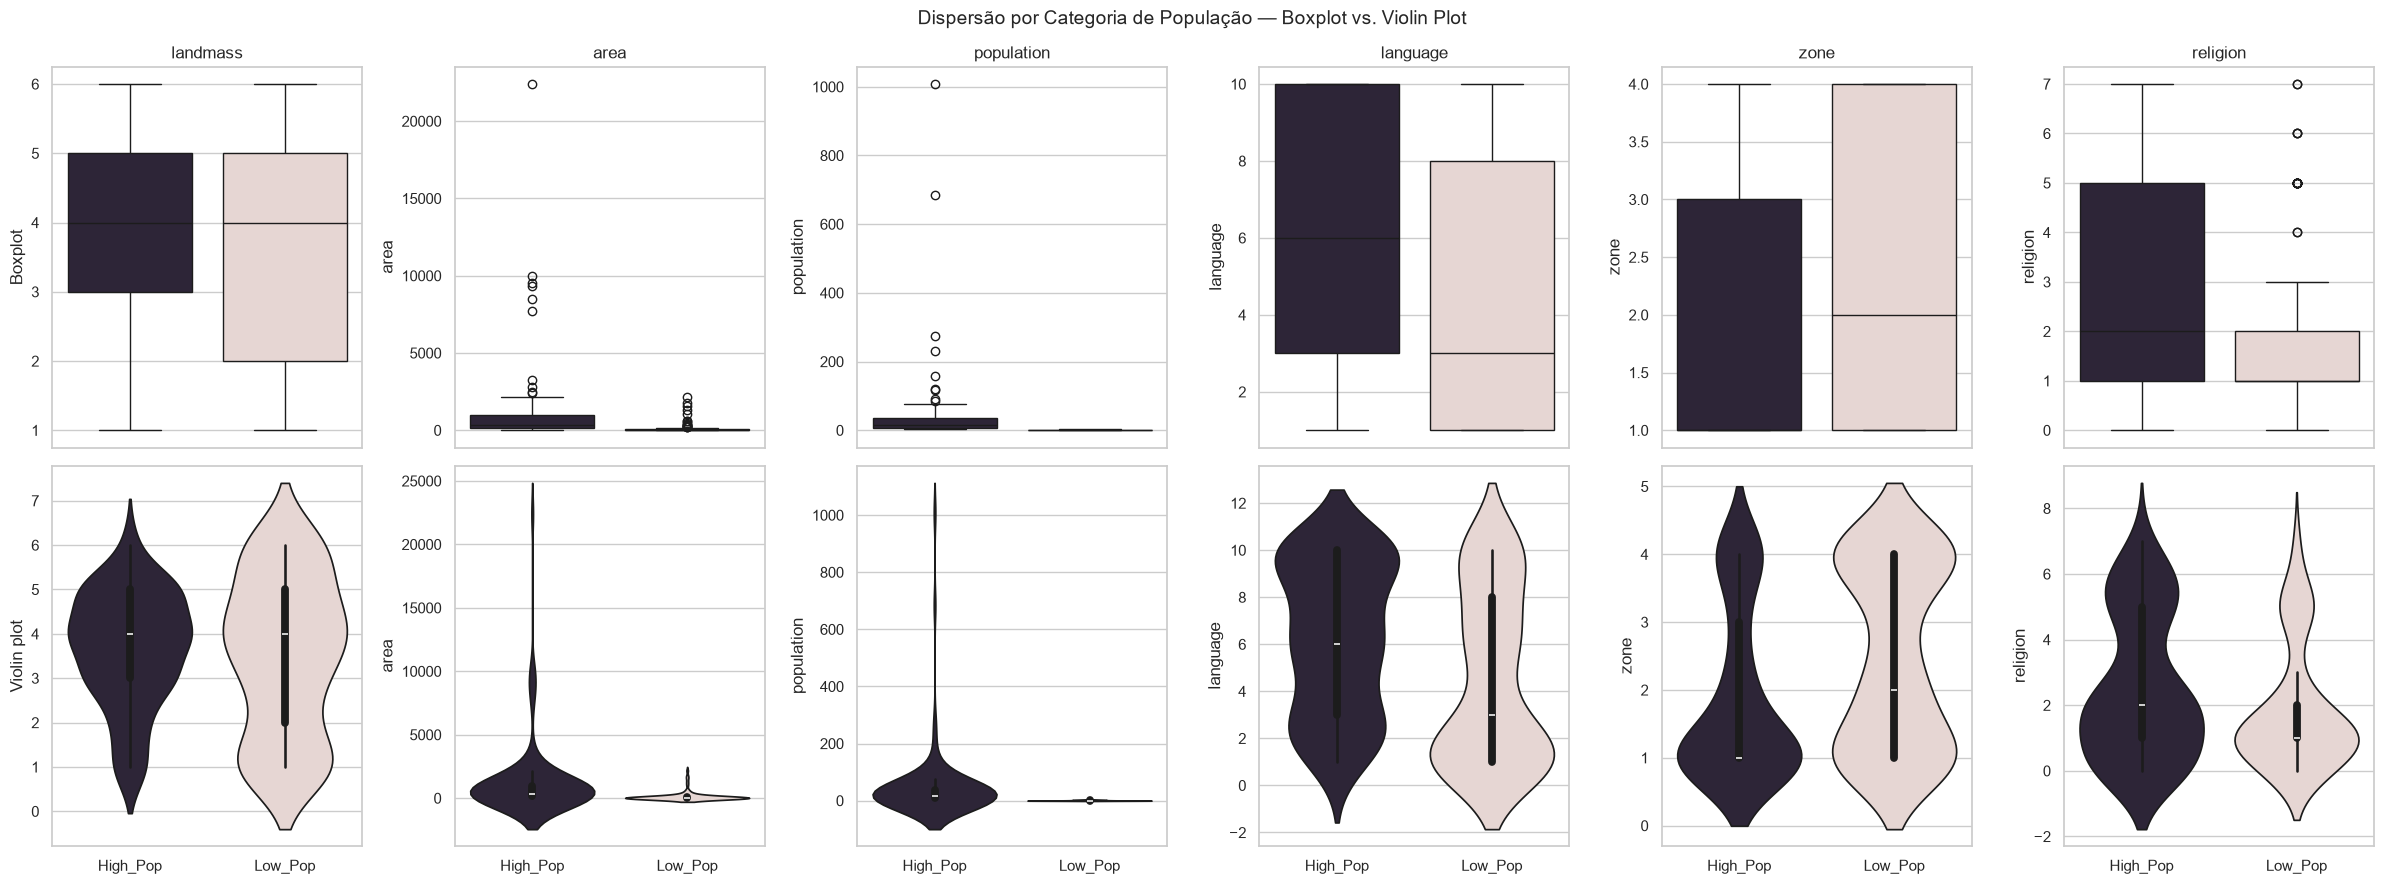

In [19]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Low_Pop": COR_CONTEXTO, "High_Pop": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="population_category", y=col, hue="population_category",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="population_category", y=col, hue="population_category",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Categoria de População — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Low_Pop" e "High_Pop"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

Com base nos gráficos de boxplot e violin plot acima, comparando as categorias 'Low_Pop' e 'High_Pop', podemos notar diferenças claras nas caixas (IQR) para algumas variáveis:

*   area e population: Estas variáveis mostram as maiores diferenças. Ambas têm caixas e distribuições nitidamente mais altas e mais amplas na categoria 'High_Pop' em comparação com 'Low_Pop'. Isso é esperado, já que 'High_Pop' engloba países com populações maiores, o que geralmente se correlaciona com áreas maiores.
*   landmass, language, zone e religion: Para estas variáveis, embora existam algumas variações, as diferenças nas caixas (IQR) entre 'Low_Pop' e 'High_Pop' são menos pronunciadas do que para area e population. No entanto, é possível observar que para language e religion, a categoria 'High_Pop' tende a ter uma distribuição ligeiramente mais alta e/ou mais espalhada. Para landmass e zone, as diferenças são mais sutis.

Estas diferenças já nos dão um bom indício de que area e population são variáveis que podem ajudar a diferenciar significativamente os países entre as categorias de população.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (nesse caso, a coluna `image`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [20]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
landmass,0.0,8.0,0.0
area,-672.0,1144.0,24.0
population,-21.0,35.0,24.0
language,-8.5,19.5,0.0
zone,-3.5,8.5,0.0
religion,-3.5,8.5,0.0


### Visualizando os Outliers

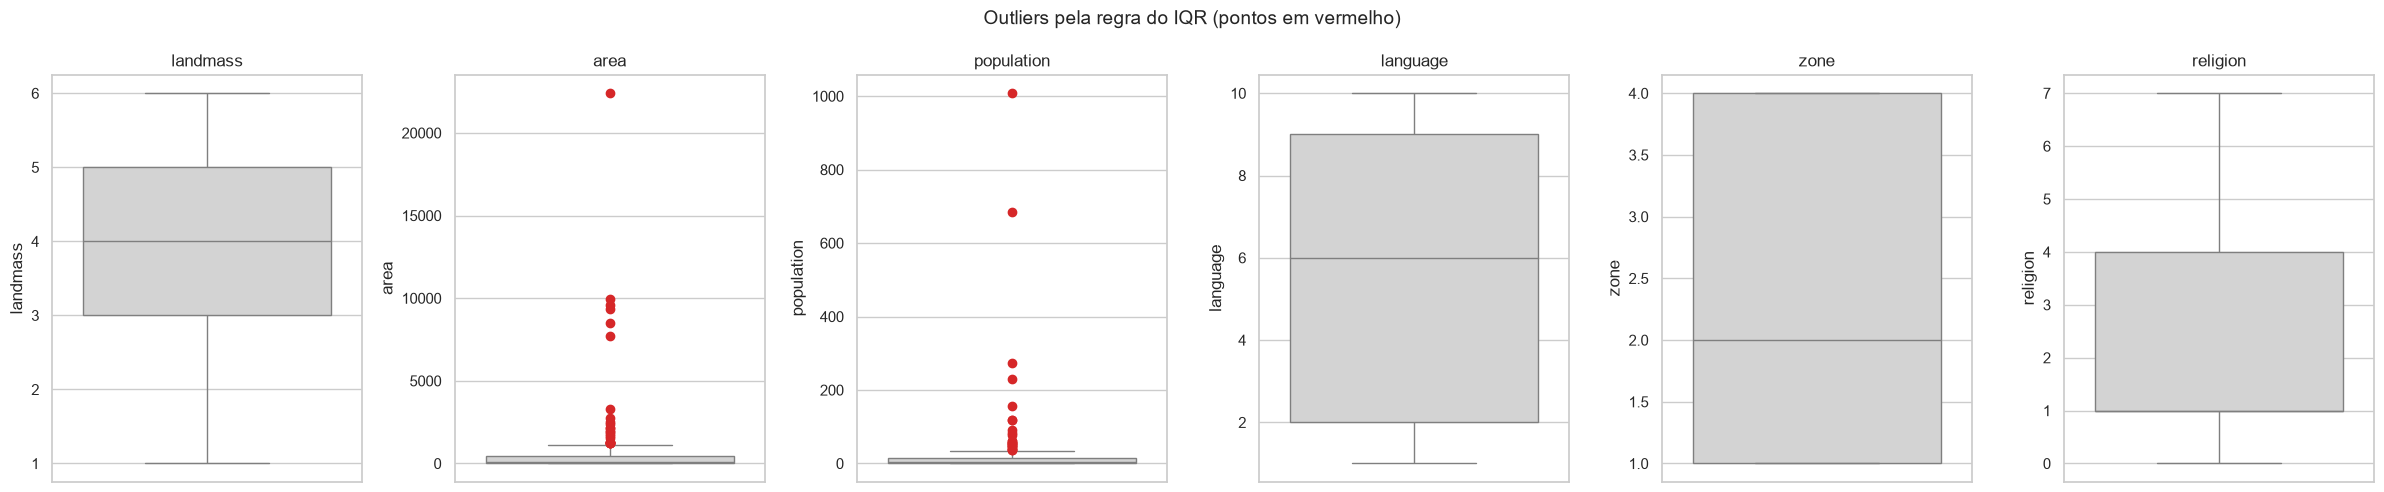

In [21]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `area` e `population`): eles parecem geograficamente plausíveis (países reais podem ter área ou população muito grandes, como Rússia, China e Índia), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

No meu caso os outliers são estatísticos pois tem muitos países com a área pequena e alguns com a área muito grande mesma coisa serve para a população pois tem países com menos de 1 milhão de pessoas enqunto outros com mais de 1 bilhão

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `image` é MAR ou MCAR (não MNAR) — a imagem de uma bandeira provavelmente falta por dificuldade de disponibilidade da imagem em si, não porque a bandeira "seria diferente". Mas aqui o volume de ausentes é grande (mais de 60% das linhas), então remover linhas sairia caro demais (perderíamos a maioria do dataset). Como a coluna `image` também não seria usada em nenhuma análise numérica ou visual desta EDA, a decisão pragmática foi remover a coluna inteira em vez de remover linhas.

No meu dataset, a coluna de Image que era a imagem das bandeiras dos países se tornava inútil pois não era utilizado para nada e mais de 60% das imagens estavam faltantes, logo optei por remover a coluna

In [22]:
if 'image' in df.columns:
    print(f"Shape antes de remover a coluna 'image': {df.shape}")
    df = df.drop(columns=['image'])
    print(f"Shape depois de remover a coluna 'image': {df.shape}")
    print("Coluna 'image' removida com sucesso.")
else:
    print("Coluna 'image' não encontrada no DataFrame.")
df.head()

Shape antes de remover a coluna 'image': (193, 32)
Shape depois de remover a coluna 'image': (193, 31)
Coluna 'image' removida com sucesso.


,name,landmass,zone,area,population,language,religion,bars,stripes,colours,...,quarters,sunstars,crescent,triangle,icon,animate,text,topleft,botright,population_category
0,Afghanistan,5,1,648,16,10,2,0,3,5,...,0,1,0,0,1,0,0,black,green,High_Pop
1,Albania,3,1,29,3,6,6,0,0,3,...,0,1,0,0,0,1,0,red,red,Low_Pop
2,Algeria,4,1,2388,20,8,2,2,0,3,...,0,1,1,0,0,0,0,green,white,High_Pop
3,American-Samoa,6,3,0,0,1,1,0,0,5,...,0,0,0,1,1,1,0,blue,red,Low_Pop
4,Andorra,3,1,0,0,6,0,3,0,3,...,0,0,0,0,0,0,0,blue,red,Low_Pop


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas geograficamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser relevante para a análise — por exemplo, exatamente os países com área ou população mais extremas, como Rússia, China e Índia, podem ser os mais interessantes de comparar) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.


Eu apliquei a tranformação logarítmica na coluna population pois estava com a distribuição muito assimétrica devido aos outliers estatísticos, a transformação reduziu essa assimetria e me deixou lidar com os outliers sem remover eles

In [23]:
df["population_log"] = np.log1p(df["population"])
df["area_log"] = np.log1p(df["area"])

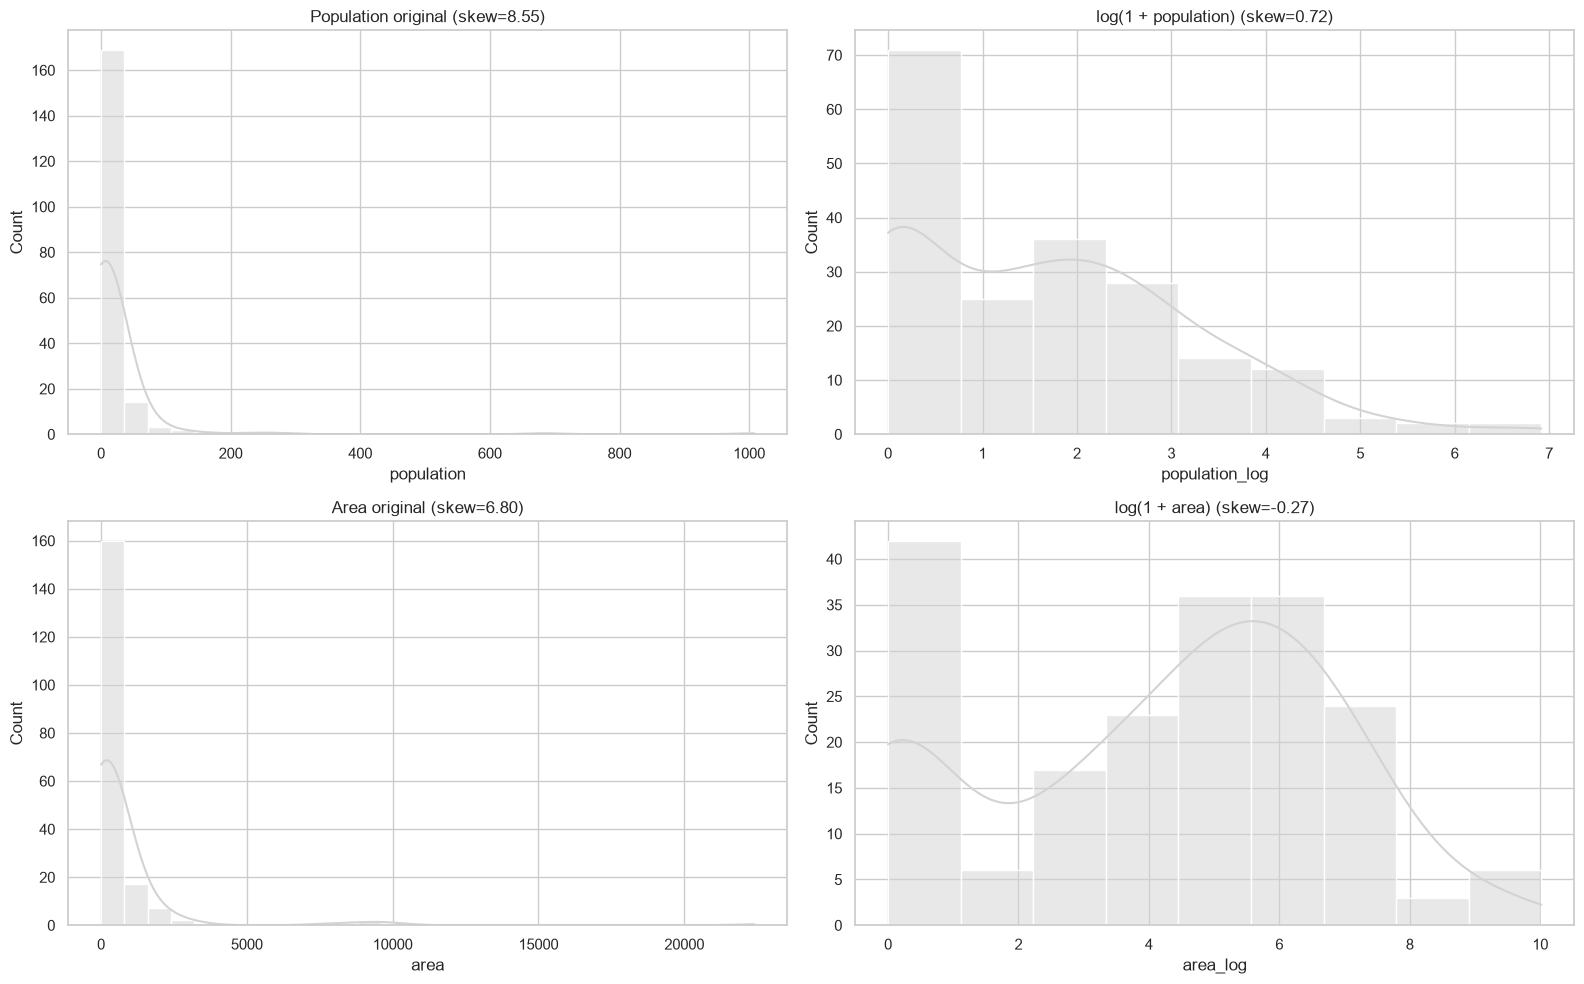

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10)) # Ajuste para 2x2 subplots

# Plots para Population
sns.histplot(data=df, x="population", kde=True, color=COR_NEUTRA, ax=axes[0, 0])
axes[0, 0].set_title(f"Population original (skew={df['population'].skew():.2f})")

sns.histplot(data=df, x="population_log", kde=True, color=COR_NEUTRA, ax=axes[0, 1])
axes[0, 1].set_title(f"log(1 + population) (skew={df['population_log'].skew():.2f})")

# Plots para Area
sns.histplot(data=df, x="area", kde=True, color=COR_NEUTRA, ax=axes[1, 0])
axes[1, 0].set_title(f"Area original (skew={df['area'].skew():.2f})")

sns.histplot(data=df, x="area_log", kde=True, color=COR_NEUTRA, ax=axes[1, 1])
axes[1, 1].set_title(f"log(1 + area) (skew={df['area_log'].skew():.2f})")

plt.tight_layout()
plt.show()

In [25]:
data_comparacao = {
    'population': {
        'skewness_original': df['population'].skew(),
        'kurtosis_original': df['population'].kurtosis(),
        'skewness_log': df['population_log'].skew(),
        'kurtosis_log': df['population_log'].kurtosis()
    },
    'area': {
        'skewness_original': df['area'].skew(),
        'kurtosis_original': df['area'].kurtosis(),
        'skewness_log': df['area_log'].skew(),
        'kurtosis_log': df['area_log'].kurtosis()
    }
}

comparacao_transformacao = pd.DataFrame(data_comparacao).T
comparacao_transformacao['delta_skewness'] = comparacao_transformacao['skewness_log'] - comparacao_transformacao['skewness_original']
comparacao_transformacao['delta_kurtosis'] = comparacao_transformacao['kurtosis_log'] - comparacao_transformacao['kurtosis_original']

print("Comparação de Skewness e Kurtosis (Original vs. Log-Transformada):")
comparacao_transformacao.round(2)

Comparação de Skewness e Kurtosis (Original vs. Log-Transformada):


,skewness_original,kurtosis_original,skewness_log,kurtosis_log,delta_skewness,delta_kurtosis
population,8.55,81.63,0.72,0.14,-7.83,-81.49
area,6.80,56.86,-0.27,-0.96,-7.07,-57.82


**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

Eu fiz a a transformação logarítmica para população e área para que o gráfico fique mais visível pois eles tavam com muitos outliers
Também crie uma nova célula para armazenar as transformações logarítmicas nas versões originais de population e area

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [26]:
VARS_QUANT_PARA_COMPARACAO = [col if col not in ['area', 'population'] else col + '_log' for col in VARS_QUANT]

desc_depois = df[VARS_QUANT_PARA_COMPARACAO].describe().T
desc_depois["skewness"] = df[VARS_QUANT_PARA_COMPARACAO].skew()
desc_depois["kurtosis"] = df[VARS_QUANT_PARA_COMPARACAO].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
landmass,3.58,4.00,1.55,1.00,6.00,-0.29,-0.90
area_log,4.16,4.72,2.65,0.00,10.02,-0.27,-0.96
population_log,1.69,1.61,1.52,0.00,6.92,0.72,0.14
language,5.36,6.00,3.50,1.00,10.00,0.08,-1.55
zone,2.21,2.00,1.31,1.00,4.00,0.42,-1.59
religion,2.20,1.00,2.06,0.00,7.00,0.82,-0.67


### Comparando "antes"x "depois""



In [27]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"].loc[['landmass', 'language', 'zone', 'religion', 'area', 'population']], # Garantindo a ordem
    "skewness_depois": desc_depois["skewness"].loc[['landmass', 'language', 'zone', 'religion', 'area_log', 'population_log']].rename(index={'area_log': 'area', 'population_log': 'population'}),
    "kurtosis_antes": desc["kurtosis"].loc[['landmass', 'language', 'zone', 'religion', 'area', 'population']],
    "kurtosis_depois": desc_depois["kurtosis"].loc[['landmass', 'language', 'zone', 'religion', 'area_log', 'population_log']].rename(index={'area_log': 'area', 'population_log': 'population'}),
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
landmass,-0.286,-0.286,-0.900,-0.900,0.000,0.000
language,0.076,0.076,-1.552,-1.552,0.000,0.000
zone,0.424,0.424,-1.593,-1.593,0.000,0.000
religion,0.819,0.819,-0.667,-0.667,0.000,0.000
area,6.800,-0.268,56.857,-0.960,-7.068,-57.818
population,8.549,0.716,81.632,0.140,-7.833,-81.493


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Os valores de kurtosis e skewness de population e area mudaram bastante mesmo sem ter removido nenhum outlier, apenas tratando, pois tinha muitos valores que eram reais porém extremos mas agora então fez sentido ter alterado tanto tendo modificado pouco

**A área ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [28]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["area_log"].dropna())
print(f"Shapiro-Wilk (antes)  — area: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g})")
print(f"Shapiro-Wilk (depois) — area_log: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g})")

Shapiro-Wilk (antes)  — area: estatística=0.3119, p-valor=2.148e-26)
Shapiro-Wilk (depois) — area_log: estatística=0.9317, p-valor=7.215e-08)


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`area` e `population`), comparando a versão original (`df_antes`) com a tratada (`df`).

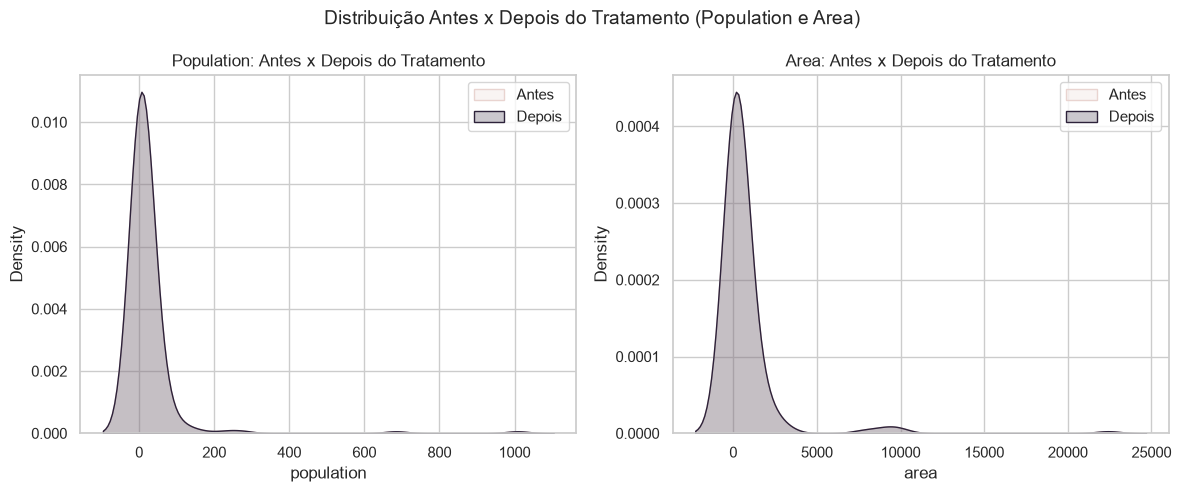

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot for population
sns.kdeplot(df_antes["population"], color=COR_CONTEXTO, fill=True, label="Antes", ax=axes[0])
sns.kdeplot(df["population"], color=COR_DESTAQUE, fill=True, label="Depois", ax=axes[0])
axes[0].set_title("Population: Antes x Depois do Tratamento")
axes[0].legend()

# Plot for area
sns.kdeplot(df_antes["area"], color=COR_CONTEXTO, fill=True, label="Antes", ax=axes[1])
sns.kdeplot(df["area"], color=COR_DESTAQUE, fill=True, label="Depois", ax=axes[1])
axes[1].set_title("Area: Antes x Depois do Tratamento")
axes[1].legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento (Population e Area)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

As curvas praticamente se sobrepõem pois as únicas linhas removidas foram as linhas das imagens das bandeiras que estavam maioria ausente e os outliers foram tratados e não removidos então a distribuição fica sobreposta  

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [30]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- mainhue ---
         absoluta  relativa
mainhue                    
red            71     0.368
blue           39     0.202
green          31     0.161
white          22     0.114
gold           19     0.098
black           5     0.026
orange          4     0.021
brown           2     0.010
\n--- topleft ---
         absoluta  relativa
topleft                    
red            56     0.290
blue           42     0.218
white          41     0.212
green          32     0.166
black          12     0.062
gold            6     0.031
orange          4     0.021
\n--- botright ---
          absoluta  relativa
botright                    
red             69     0.358
blue            46     0.238
green           40     0.207
white           17     0.088
black            9     0.047
gold             9     0.047
brown            2     0.010
orange           1     0.005
\n--- population_category ---
                     absoluta  relativa
population_category                    
Low_Pop      

#### Visualizando as frequências

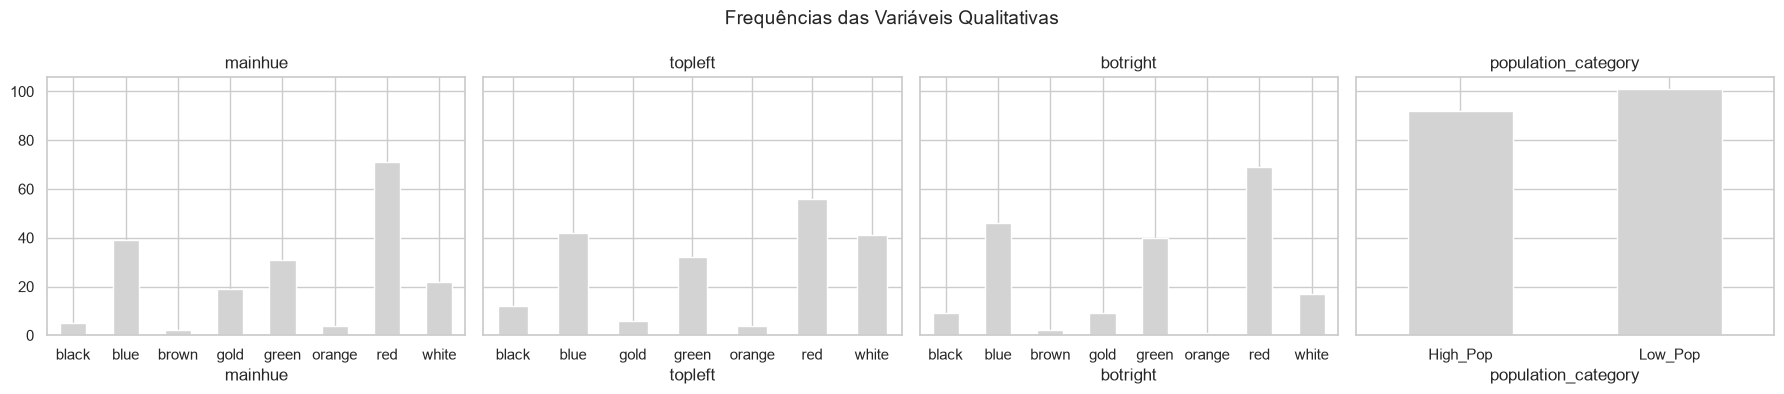

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True) # Alterado para 1 linha e 4 colunas
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

# Esta parte do código não é mais necessária, pois a grade agora se ajusta aos dados.
# for ax in axes[len(VARS_QUALI):]:
#     ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Sim, algumas variáveis qualitativas apresentam certo desbalanceamento, principalmente mainhue e botright, nas quais a categoria red concentra grande parte das observações, enquanto outras categorias possuem poucas ocorrências. Já population_category apresenta uma distribuição mais equilibrada entre High_Pop e Low_Pop. Esse desbalanceamento deve ser considerado na análise bivariada, pois categorias com poucas observações podem dificultar a interpretação dos cruzamentos e gerar resultados menos representativos.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo a própria variável population_category.


In [32]:
from scipy.stats import entropy
import numpy as np # Importar numpy para np.log2
import pandas as pd # Importar pandas para pd.Series

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    if contagens.min() == 0: # Adicionando verificação para evitar divisão por zero
        razao = np.inf # Se houver uma classe com 0 ocorrências, a razão é infinita
    else:
        razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    # n_classes > 1 é importante para evitar log2(0) ou divisão por zero
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 and np.log2(n_classes) != 0 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

# A coluna 'doenca_cardiaca' não existe neste dataset (`flags.csv`).
# Utilizamos 'population_category' como a variável alvo adaptada para este contexto.
# Como 'population_category' já está incluída em VARS_QUALI, podemos usar VARS_QUALI diretamente.
vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
mainhue,8.0,35.5,0.809
topleft,7.0,14.0,0.863
botright,8.0,69.0,0.774
population_category,2.0,1.1,0.998


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E a própria variável `population_category` — está balanceada o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

`population_category` foi criada a partir da mediana da população, então por construção ela fica bem balanceada (razão de desbalanceamento próxima de 1 e entropia próxima de 1) — o que é ótimo para não distorcer comparações mais à frente. Já `mainhue`, `topleft` e `botright` são bem mais desbalanceadas (razão de desbalanceamento alta e entropia bem abaixo de 1), porque cores como branco e vermelho dominam a maioria das bandeiras, enquanto cores como laranja ou preto aparecem em pouquíssimos países. Isso não impede a análise bivariada, mas significa que qualquer cruzamento envolvendo essas variáveis de cor deve ser lido com cuidado nas categorias muito raras, onde o tamanho da amostra é pequeno.

### Análise Bivariada


Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com a variável proxy `population_category`.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

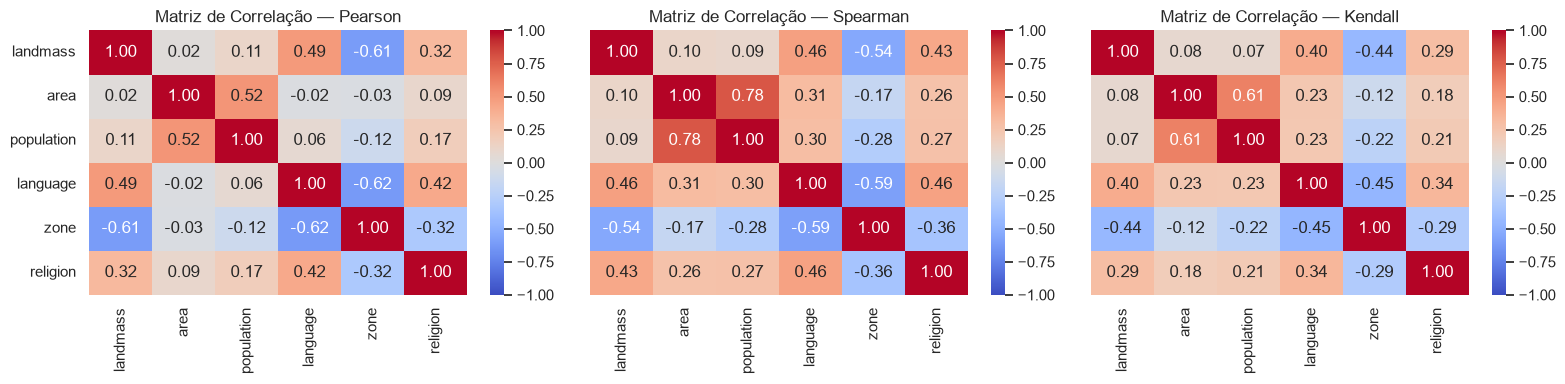

In [33]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhi `area` x `population` por um motivo de domínio, não só estatístico: espera-se que países com área maior tenham, em média, mais espaço para abrigar populações maiores, o que torna esse par um bom candidato pra visualizar uma tendência real (mesmo sabendo que a relação é fraca — vários dos países mais populosos do mundo, como a Índia, não são os maiores em área).

Nota para quando vocês replicarem no dataset de vocês: nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

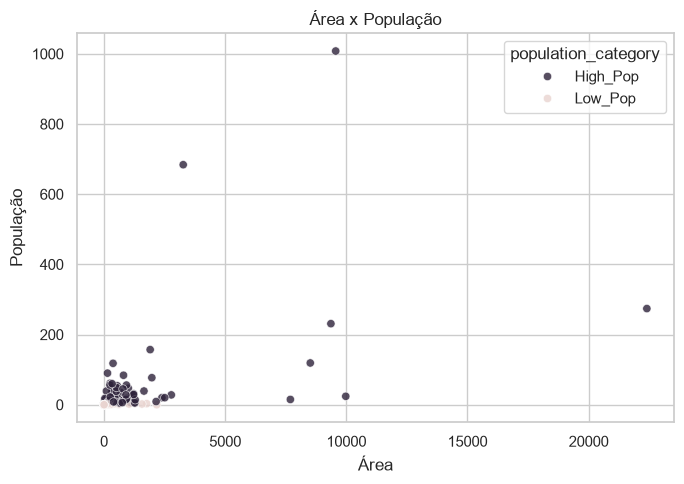

In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="area", y="population", hue="population_category",
                palette={"Low_Pop": COR_CONTEXTO, "High_Pop": COR_DESTAQUE}, alpha=0.8)
plt.title("Área x População")
plt.xlabel("Área")
plt.ylabel("População")
plt.tight_layout()
plt.show()


**Pra discutir:** existe uma tendência visível (países com área maior tendem a ter população maior)? As duas categorias de população ocupam regiões diferentes do gráfico, ou estão misturadas?

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test (2 grupos, como `population_category`), e **Kruskal-Wallis** no lugar da ANOVA (3+ grupos, como `mainhue`). Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [35]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_low = df.loc[df["population_category"] == "Low_Pop", col]
    grupo_high = df.loc[df["population_category"] == "High_Pop", col]

    stat_t, p_t = stats.ttest_ind(grupo_low, grupo_high, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_low, grupo_high)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")


,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
landmass,0.47512,0.65637,True
area,0.00043,0.00000,True
population,0.00082,0.00000,True
language,0.00079,0.00027,True
zone,0.00262,0.00207,True
religion,0.01998,0.01846,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, já que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`mainhue` (cor predominante da bandeira) tem 8 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

ANOVA          — population entre categorias de mainhue: estatística=2.125, p-valor=0.043028
Kruskal-Wallis — population entre categorias de mainhue: estatística=14.987, p-valor=0.03617


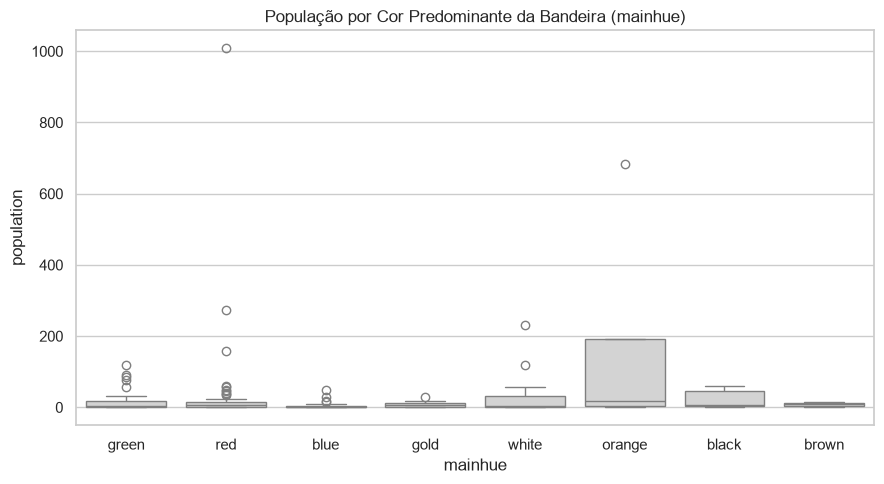

In [36]:
grupos_mainhue = [grupo["population"].values for _, grupo in df.groupby("mainhue")]

stat_anova, p_anova = stats.f_oneway(*grupos_mainhue)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_mainhue)          # não-paramétrico

print(f"ANOVA          — population entre categorias de mainhue: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — population entre categorias de mainhue: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="mainhue", y="population", color=COR_NEUTRA)
plt.title("População por Cor Predominante da Bandeira (mainhue)")
plt.tight_layout()
plt.show()


**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `mainhue`? Como já sabemos que `population` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal — a ANOVA fica só como contraste.

#### Qualitativa x Qualitativa

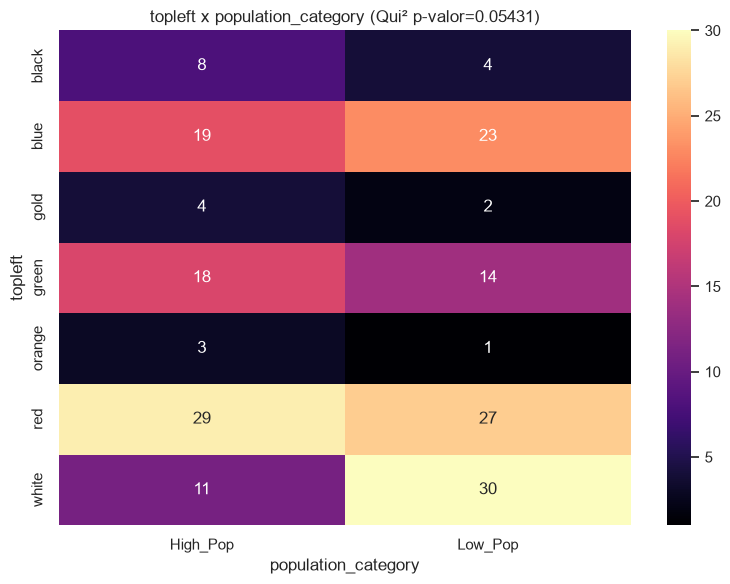

In [37]:
contingencia_cores = pd.crosstab(df["topleft"], df["population_category"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_cores)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(contingencia_cores, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"topleft x population_category (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()


**Pra discutir:** o p-valor do Qui-Quadrado indica que `topleft` e `population_category` são independentes, ou há associação estatisticamente significativa entre elas?

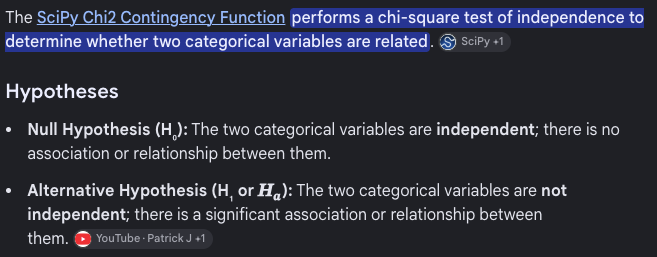

#### Outliers bivariados

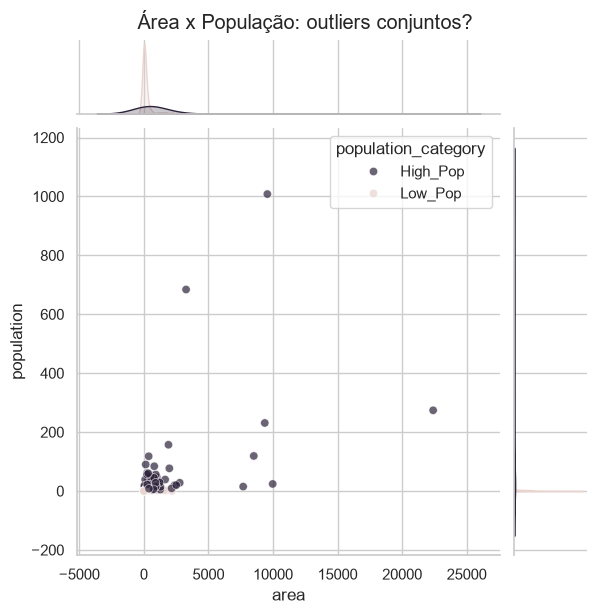

In [38]:
sns.jointplot(data=df, x="area", y="population", hue="population_category",
              palette={"Low_Pop": COR_CONTEXTO, "High_Pop": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Área x População: outliers conjuntos?", y=1.02)
plt.show()


**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3), mas que se destaca aqui como uma combinação incomum de `area` e `population`?

#### Análise Multivariada

##### Matriz de Correlação

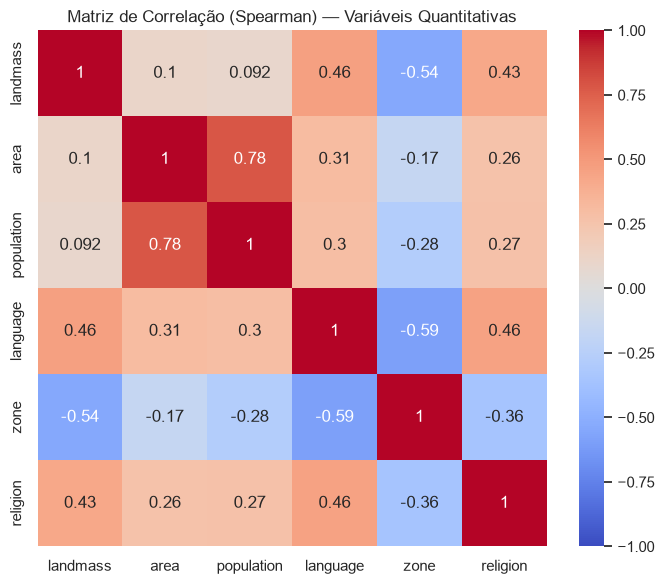

In [39]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

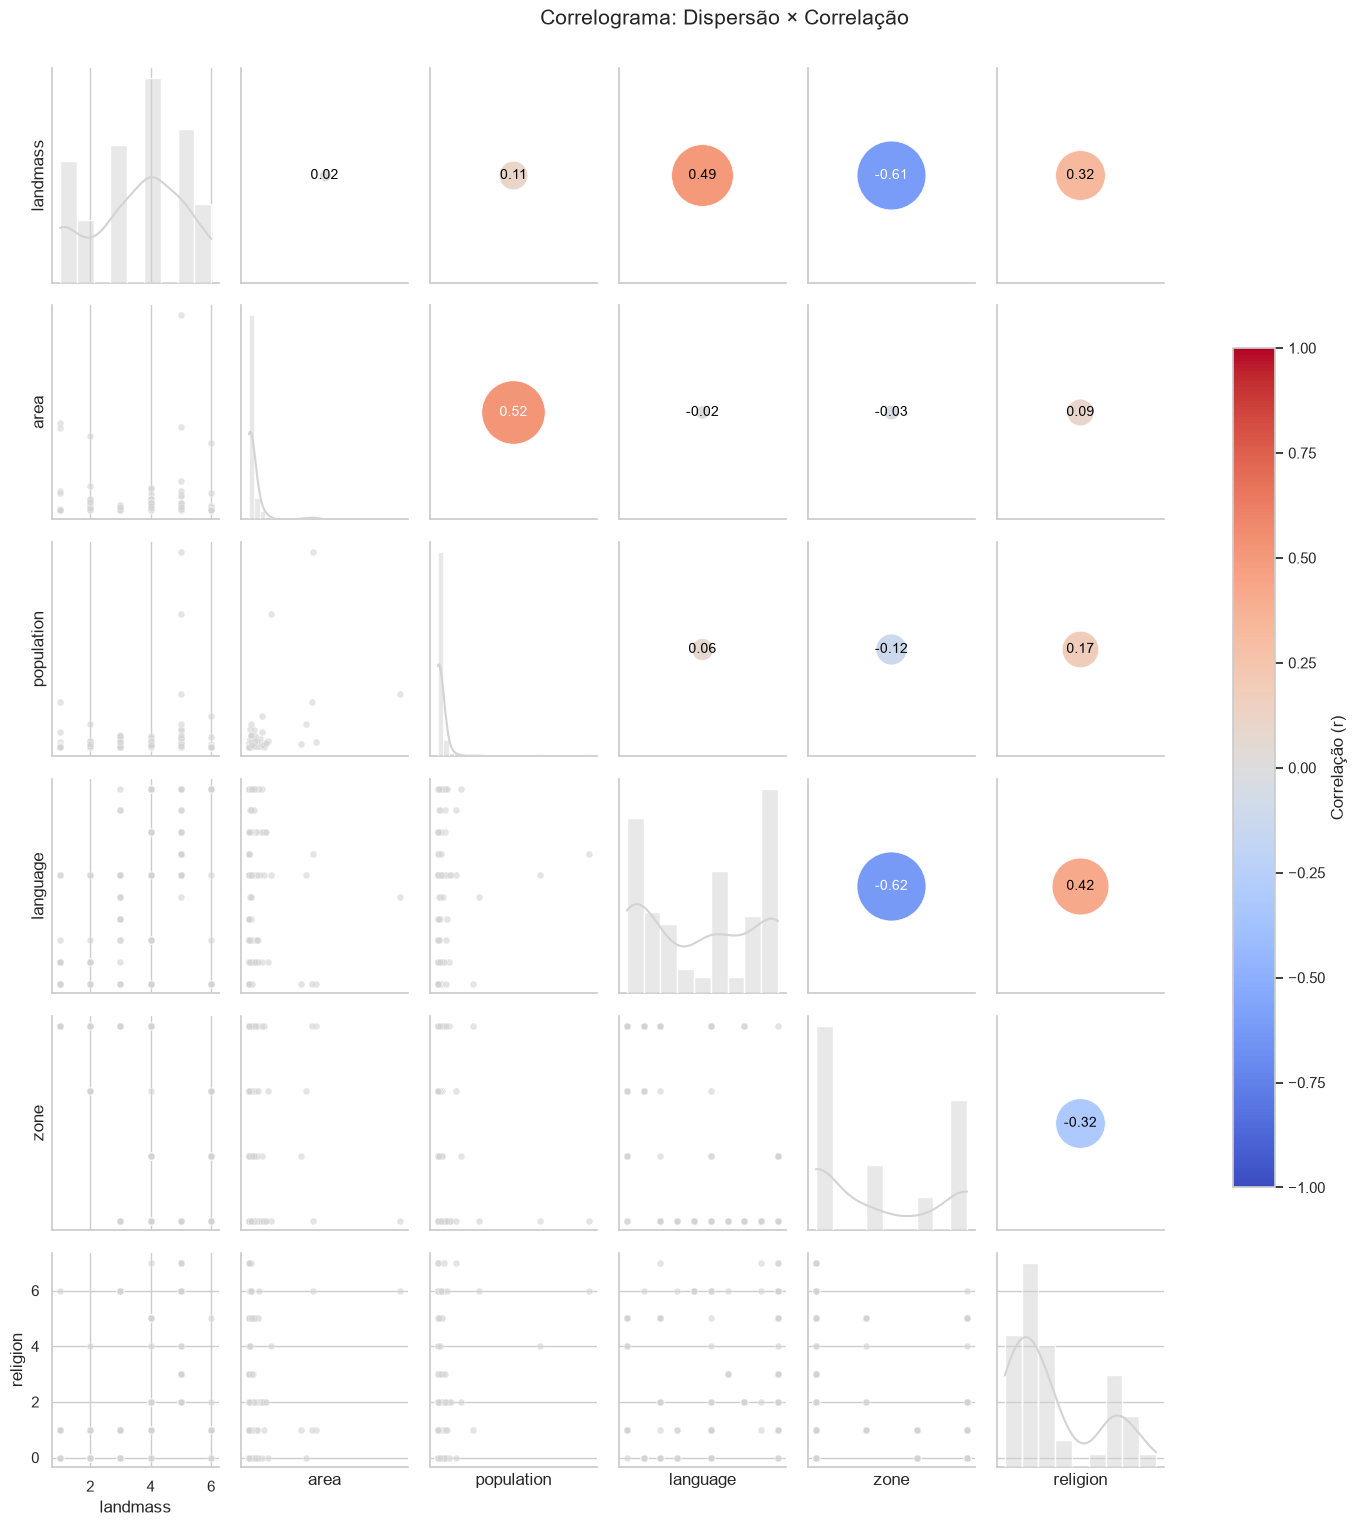

In [40]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


Com isso, fechamos a análise bivariada e multivariada: mesmo um dataset sem uma variável-alvo natural tinha variáveis qualitativas suficientes (`mainhue`, `topleft`, `botright`, `population_category`) para sustentar cruzamentos qualitativa x qualitativa, quantitativa x qualitativa, quantitativa x quantitativa e a análise multivariada — a afirmação anterior de que isso "não seria possível" estava incorreta.

In [41]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [42]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `heart`, que não foi alterado)
df_raw = df_antes.copy()
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False, sep=";")

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ..\data\raw\dataset.csv — 193 linhas x 31 colunas


In [43]:
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False, sep=";")

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")
print(f"Colunas removidas: {df_raw.shape[1] - df.shape[1]}")

Clean salvo em ..\data\clean\dataset.csv — 193 linhas x 33 colunas
Linhas removidas no tratamento: 0
Colunas removidas: -2


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




## Declaração de IA

A Inteligência Artificial foi utilizada como ferramenta de apoio durante a realização da atividade, principalmente para auxiliar na elaboração e correção de códigos, criação e interpretação de gráficos, esclarecimento de dúvidas e explicação de conceitos. As informações e resultados obtidos foram revisados e utilizados como suporte para a realização do trabalho